In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
from scipy import stats
import scanpy as sc
import anndata as ad

In [2]:
import scHPT

In [3]:
import matplotlib.colors as mplc
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.offsetbox import (DrawingArea, OffsetImage,AnnotationBbox)

# Nutlin data

## Preprocessing data

The nutlin data ('Idasanutlin_24hr_expt1') is downloaded from https://figshare.com/s/139f64b495dea9d88c70. [McFarland, J.M., Paolella, B.R., Warren, A. et al. Nat Commun 2020.]

In [2]:
# read data
nutlin_adata=sc.read_10x_mtx(path='data/Idasanutlin_24hr_expt1/Idasanutlin_24hr_expt1/')
ctrl_adata=sc.read_10x_mtx(path='data/DMSO_24hr_expt1/DMSO_24hr_expt1/')
nutlin_meta=pd.read_csv('data/Idasanutlin_24hr_expt1/Idasanutlin_24hr_expt1/classifications.csv',index_col=0)
ctrl_meta=pd.read_csv('data/DMSO_24hr_expt1/DMSO_24hr_expt1/classifications.csv',index_col=0)
nutlin_adata.obs=nutlin_meta
ctrl_adata.obs=ctrl_meta

In [3]:
# combine adatas
adatas = {"nutlin":nutlin_adata, "control": ctrl_adata}
adatas = ad.concat(adatas, label="condition",  join="outer")
adatas.obs_names_make_unique()
adatas2=adatas[adatas.obs.cell_quality=='normal']

C:\Users\17794\AppData\Roaming\Python\Python39\site-packages\anndata\_core\anndata.py:1828: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [4]:
# filter cells and genes
sc.pp.filter_cells(adatas2, min_genes=200)
sc.pp.filter_genes(adatas2, min_cells=3)
# annotate the group of mitochondrial genes as "mt"
adatas2.var["mt"] = adatas2.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(
    adatas2, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True
)
adatas2 = adatas2[adatas2.obs.n_genes_by_counts < 6000, :]
adatas2 = adatas2[adatas2.obs.pct_counts_mt < 20, :].copy()

C:\ProgramData\anaconda\lib\site-packages\scanpy\preprocessing\_simple.py:139: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['n_genes'] = number


In [5]:
# normalize
sc.pp.normalize_total(adatas2, target_sum=1e4)
sc.pp.log1p(adatas2)
sc.pp.highly_variable_genes(adatas2, min_mean=0.0125, max_mean=3, min_disp=0.5,n_top_genes=6000)
adatas2.raw = adatas2
adatas2 = adatas2[:, adatas2.var.highly_variable]
sc.pp.scale(adatas2, max_value=10)

C:\ProgramData\anaconda\lib\site-packages\scanpy\preprocessing\_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [7]:
# pca, UMAP
sc.tl.pca(adatas2, svd_solver="arpack")
sc.pp.neighbors(adatas2, n_neighbors=10, n_pcs=40)
sc.tl.umap(adatas2)

C:\ProgramData\anaconda\lib\site-packages\sklearn\manifold\_spectral_embedding.py:260: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [8]:
# adjust metadata
adatas2.obs=adatas2.obs.drop(columns=['num_SNPs', 'singlet_dev', 'singlet_dev_z',
                                      'singlet_margin', 'singlet_z_margin', 'doublet_z_margin',
                                      'tot_reads', 'doublet_dev_imp', 'doublet_CL1',
                                      'doublet_CL2', 'percent.mito',
                                      'cell_det_rate', 'cell_quality', 'doublet_GMM_prob', 
                                      'n_genes', 'n_genes_by_counts', 'total_counts',
                                      'total_counts_mt', 'pct_counts_mt'])
adatas2.obs=adatas2.obs.rename(columns={"singlet_ID": 'cell_type'})

In [9]:
adatas2.obs

,cell_type,DepMap_ID,condition
barcode,,,
AAACCTGAGATCCTGT-1,RERFLCAD1_LUNG,ACH-000791,nutlin
AAACCTGCAGAGCCAA-1,SKMEL2_SKIN,ACH-001190,nutlin
AAACCTGCAGCGTCCA-1,RCM1_LARGE_INTESTINE,ACH-000565,nutlin
AAACCTGGTACCTACA-1,LS1034_LARGE_INTESTINE,ACH-000252,nutlin
AAACCTGGTGTATGGG-1,SH10TC_STOMACH,ACH-000764,nutlin
...,...,...,...
TTTGTCAAGCTCCTCT-1,CAOV3_OVARY,ACH-000713,control
TTTGTCAAGTCTCAAC-1,RCC10RGB_KIDNEY,ACH-000189,control
TTTGTCAAGTTGTAGA-1,IALM_LUNG,ACH-000672,control


In [10]:
#save
adatas2.write('data/Idasanutlin_24hr_expt1_processed.h5ad')

# Test 1

In [4]:
adata=sc.read('data/Idasanutlin_24hr_expt1_processed.h5ad')

In [5]:
type_full_name=list(adata.obs.cell_type.cat.categories)
type_simple_name=[i.split('_')[0] for i in type_full_name]
type_conv_dict=dict(zip(type_full_name,type_simple_name))
adata.obs.cell_type.cat.rename_categories(type_conv_dict,inplace=True)

C:\Users\17794\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\categorical.py:2631: FutureWarning: The `inplace` parameter in pandas.Categorical.rename_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  res = method(*args, **kwargs)


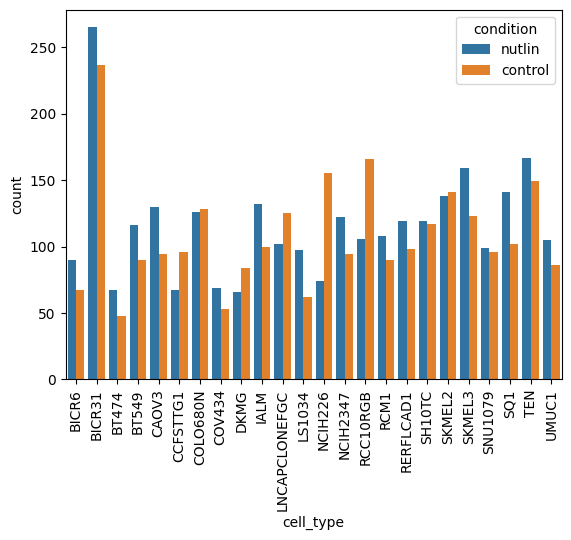

In [6]:
sns.countplot(data=adata.obs, x="cell_type",hue='condition')
plt.xticks(rotation=90)
plt.show()

In [7]:
# Y = TP53_SIGNALING_PATHWAY
with open("KEGG_P53_SIGNALING_PATHWAY.v2023.2.Hs.tsv", "r") as filestream:
    for line in filestream:
        contents=line.split(',')
        if contents[0].startswith('GENE_SYMBOLS'):
            geneset=contents
            geneset[0]=(geneset[0].split('\t'))[1]
            geneset[-1]=(geneset[-1].split('\n'))[0]

In [8]:
geneset_search=list(set(geneset) & set(adata.var_names))
len(geneset_search),len(geneset)

(48, 69)

In [9]:
adata.obs['TP53_path'] = list((adata[:,geneset_search].X.copy()).mean(axis=1).flatten())

In [10]:
res=scHPT.permute_test(adata=adata, Y_column='TP53_path', T_column='condition',
                       pert_name='nutlin', ctrl_name='control',n_perm=1000, verbose=True)

In [11]:
pval_final_all=res[0]
tau_hat_all=res[4]
tau_sd_all=res[5]

In [12]:
pval_final_all # test1 pvalue

0.001

In [13]:
tau_hat_all,tau_sd_all # estimation of tau and sd(tau)

(0.04585340378671728, 0.005910612738346187)

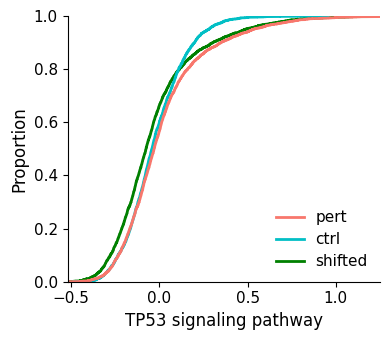

In [14]:
# draw shifted cdf plot
data_df=(pd.DataFrame([list(adata.obs.TP53_path),
                       list(adata.obs.condition),
                       list(adata.obs.cell_type)])).T
data_df.columns=['Yobs','pert','group']
pert_dict={'nutlin':1,'control':0}
data_df["pert"].replace(pert_dict, inplace=True)
shifted_df=data_df[data_df.pert==1].copy()
data0_obs=(data_df[data_df.pert==0])['Yobs'].values
data1_obs=(data_df[data_df.pert==1])['Yobs'].values
tau_hat=np.mean(data1_obs)-np.mean(data0_obs)
shifted_df['Yobs']=shifted_df['Yobs']-tau_hat
shifted_df['pert']=2
data_df_drawcdf=pd.concat([data_df, shifted_df], ignore_index=True, sort=False)
rename_dict = {0: 'ctrl', 1: 'pert', 2: 'shifted'}
data_df_drawcdf['pert'] = data_df_drawcdf['pert'].replace(rename_dict)

# set color
palette = {
    'ctrl': '#02BFC5',
    'pert': '#F8776C',
    'shifted': 'g'
}

# set fig
plt.figure(figsize=(4, 3.5))
ax = sns.ecdfplot(data=data_df_drawcdf, x="Yobs", hue="pert", palette=palette, linewidth=2)
sns.despine()

legend = ax.legend_
if legend:
    legend.set_frame_on(False)
    legend.set_title(None) 
    for text in legend.get_texts():
        text.set_fontsize(11)  

plt.xlabel('TP53 signaling pathway', fontsize=12)
plt.ylabel('Proportion',fontsize=12)
plt.xlim([-0.52,1.25])
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig('all_figs/nutlin+hprt1/nutlin1.svg', format='svg')  # save fig
plt.show()

In [15]:
# Test1 for TP53 Mutant cells
TP53WT_cell_type=['LNCAPCLONEFGC','DKMG','NCIH226','RCC10RGB','SNU1079','CCFSTTG1','COV434']
adata2=adata[~adata.obs.cell_type.isin(TP53WT_cell_type)]

In [16]:
res=scHPT.permute_test(adata=adata2, Y_column='TP53_path', T_column='condition',
                       pert_name='nutlin', ctrl_name='control',n_perm=1000, verbose=True)

In [17]:
pval_final_mutant=res[0]
pval_final_mutant

0.751

# Test 2

In [18]:
final_res_df=scHPT.permute_test_group(adata=adata, Y_column='TP53_path', T_column='condition',
                                      group_column='cell_type', pert_name='nutlin', ctrl_name='control',
                                      n_cell_min=30, n_perm=1000, verbose=True)

Finish permutation : 0
Finish permutation : 100
Finish permutation : 200
Finish permutation : 300
Finish permutation : 400
Finish permutation : 500
Finish permutation : 600
Finish permutation : 700
Finish permutation : 800
Finish permutation : 900


In [19]:
final_res_df

,group,p_val,tau_hat,tau_sd,tau_star,sks_obs
0,NCIH226,0.084,0.481058,0.039319,0.460629,0.225109
1,CCFSTTG1,0.089,0.395079,0.045106,0.35602,0.222792
2,LNCAPCLONEFGC,0.736,0.394608,0.023894,0.394608,0.157882
3,LS1034,0.989,-0.032053,0.024862,-0.04497,0.121051
4,BICR6,0.996,-0.040551,0.023619,-0.052822,0.116252
5,COV434,0.996,0.169712,0.024432,0.169712,0.109653
6,BT474,0.996,-0.00579,0.021221,-0.009465,0.106343
7,RCC10RGB,0.997,0.377093,0.030725,0.350487,0.102523
8,NCIH2347,0.999,0.009902,0.018359,0.000364,0.099407
9,BT549,1.0,-0.005047,0.018196,-0.020803,0.09387


In [20]:
final_res_df.to_csv('Nutlin_test2_res_df.csv')

In [18]:
final_res_df = pd.read_csv('Nutlin_test2_res_df.csv',index_col=0)

In [19]:
err_list=[]
for i in range(len(final_res_df)):
    err_list.append(stats.norm.interval(1-0.05, loc=0, scale=final_res_df.iloc[i,:]['tau_sd'])[1])
final_res_df['95_err']=err_list
final_res_df.sort_values('tau_hat', inplace=True,ascending=True)

In [20]:
all_min,all_max=stats.norm.interval(1-0.05, loc=tau_hat_all, scale=tau_sd_all)

In [21]:
def draw_brace(ax, xspan, yy, text):
    """Draws an annotated brace on the axes."""
    xmin, xmax = xspan
    xspan = xmax - xmin
    ax_xmin, ax_xmax = ax.get_xlim()
    xax_span = ax_xmax - ax_xmin

    ymin, ymax = ax.get_ylim()
    yspan = ymax - ymin
    resolution = int(xspan/xax_span*100)*2+1 # guaranteed uneven
    beta = 500./xax_span # the higher this is, the smaller the radius

    x = np.linspace(xmin, xmax, resolution)
    x_half = x[:int(resolution/2)+1]
    y_half_brace = (1/(1.+np.exp(-beta*(x_half-x_half[0])))
                    + 1/(1.+np.exp(-beta*(x_half-x_half[-1]))))
    y = np.concatenate((y_half_brace, y_half_brace[-2::-1]))
    y = yy + (.05*y - .01)*yspan # adjust vertical position

    ax.autoscale(False)
    ax.plot(x, y, color='black', lw=1)

    ax.text((xmax+xmin)/2., yy+.07*yspan, text, ha='center', va='bottom')

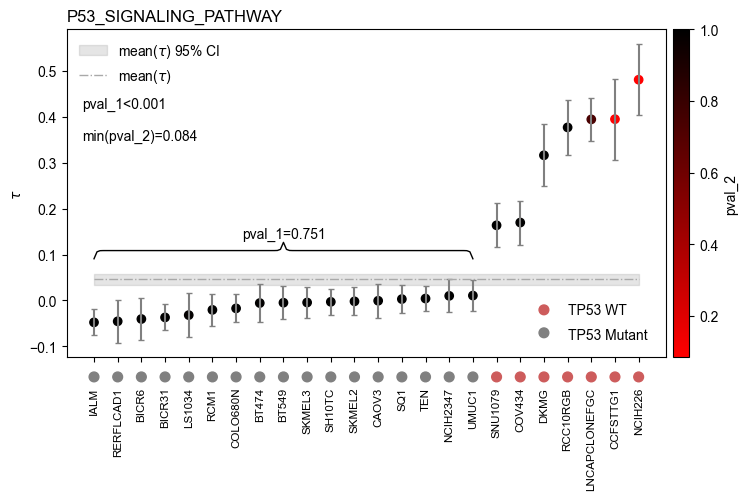

In [23]:
with plt.rc_context({'figure.figsize': (8, 5.15),'font.sans-serif':['Arial']}):
    rbcmap = mplc.LinearSegmentedColormap.from_list("", ["red","black"])
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.errorbar(final_res_df['group'], final_res_df['tau_hat'], yerr = final_res_df['95_err'], ls = "None", capsize=2,color = "grey")
    #im=ax.scatter(final_res_df['group'], final_res_df['tau_hat'],  marker = "o", c = -np.log10(final_res_df['p_val'].values.astype(np.float64)),cmap=rbcmap)
    im=ax.scatter(final_res_df['group'], final_res_df['tau_hat'],  marker = "o", c = final_res_df['p_val'],cmap=rbcmap)
    ax.set_ylabel(r'$\tau$')
    cbar=plt.colorbar(im,ax=ax,pad=0.01)
    #cbar.set_label('-log10(p-val)', rotation=90)
    cbar.set_label('pval_2', rotation=90)
    for i,(g,t) in enumerate(zip(np.linspace(0,len(final_res_df)-1,len(final_res_df)),ax.get_xticklabels())):
        t.set_rotation(90)
        t.set_fontsize(8.4)
        t.set_position((i,-0.06))
    
    all_CI_min,all_CI_max=stats.norm.interval(1-0.05, loc=tau_hat_all, scale=tau_sd_all)
    ax.fill_between(range(len(final_res_df)),all_CI_min,all_CI_max,alpha=0.2, color='grey', label = r'mean($\tau$) 95% CI')
    ax.hlines(y=tau_hat_all, xmin=0, xmax=len(final_res_df)-1, linewidth=1, color='darkgrey',linestyle='-.',label=r'mean($\tau$)')
    plt.legend(frameon=False)
    for i in range(len(final_res_df)):
        if i>len(final_res_df)-8:
            da = DrawingArea(8, 8, 4, 4)
            p = mpatches.Circle((0, 0), 3.5,color='indianred')
            da.add_artist(p)
        else:
            da = DrawingArea(8, 8, 4, 4)
            p = mpatches.Circle((0, 0), 3.5,color='grey')
            da.add_artist(p)
        ab = AnnotationBbox(da, (i,0),
                            xybox=(0, -10),
                            xycoords=("data", "axes fraction"),
                            box_alignment=(0.5, 1),
                            boxcoords="offset points",
                            bboxprops={"edgecolor" : "none"})
        ax.add_artist(ab)
    
    da = DrawingArea(7, 7, 3.5, 3.5)
    p = mpatches.Circle((0, 0), 3.5,color='indianred')
    da.add_artist(p)
    ab = AnnotationBbox(da, (19,0.16),
                        xybox=(0, 0),
                        xycoords=("data", "axes fraction"),
                        box_alignment=(0.5, 1),
                        boxcoords="offset points",
                        bboxprops={"edgecolor" : "none"})
    ax.add_artist(ab)
    ax.text(20,-0.03,'TP53 WT')
    da = DrawingArea(7, 7, 3.5, 3.5)
    p = mpatches.Circle((0, 0), 3.5,color='grey')
    da.add_artist(p)
    ab = AnnotationBbox(da, (19,0.09),
                        xybox=(0, 0),
                        xycoords=("data", "axes fraction"),
                        box_alignment=(0.5, 1),
                        boxcoords="offset points",
                        bboxprops={"edgecolor" : "none"})
    ax.add_artist(ab)
    ax.text(20,-0.085,'TP53 Mutant')
    ax.text(-0.5,0.42,'pval_1<0.001')
    ax.text(-0.5,0.35,'min(pval_2)={}'.format(round(final_res_df.p_val.min(),3)))
    draw_brace(ax, (0, 16), 0.08, 'pval_1={}'.format(pval_final_mutant))
    plt.title('P53_SIGNALING_PATHWAY',loc='left')
    plt.tight_layout()
    plt.savefig('all_figs/nutlin+hprt1/nutlin2.svg', format='svg')
    plt.show()